# AI-Enhanced Reorder Point & Inventory Optimisation
**AI in Operations · Day 2, Session II exercise (slide 35)** · Harsh Verma (as25dxb024)

> **Objective (slide 35):** *Enhance the reorder-point calculator and sensitivity analysis by introducing predictive intelligence, adaptive decision-making, and real-time optimization.*

The starting point is the class calculator: `reorder point = daily demand × lead time + safety stock`, with all three inputs typed in by hand and a "sensitivity analysis" that changes one input at a time. This notebook replaces the hand-typed demand and safety stock with values learned from data, models lead time as uncertain instead of fixed, and replaces the one-at-a-time charts with optimisation:

| Slide 35 asks for | Where it is done | What it replaces in the class calculator |
|---|---|---|
| **1. Demand forecasting** with ML (time series, regression, LSTM), using history, seasonality, promotions and external factors; new data can be added and forecasts update continuously | Sections 5, 5.1, 10 | the fixed "daily demand" number |
| **2. Dynamic safety stock** from a probabilistic model (demand **and** lead-time uncertainty) and **Monte Carlo** simulation, using the slide's formula | Section 7 | the fixed "safety stock" number |
| **3. AI-driven sensitivity analysis**: **Bayesian optimisation** finds the optimal reorder point **under constraints**, instead of manual parameter sweeps | Sections 8–9 | the one-at-a-time sensitivity charts |
| Real-time optimisation | Section 10: the whole pipeline re-runs every day as each new day of raw data arrives (a day-by-day replay of the final week) | — |

**Data:** [FreshRetailNet-50K](https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K) (Dingdong, 2025, CC BY 4.0): 50,000 store–product daily sales histories of fresh groceries in 18 Chinese cities, with **promotions**, **weather**, **holidays** and **hour-by-hour stock-out records**. Per the slide's *"no sharing of data with peers"* rule, this notebook works on one store chosen by a random seed derived from the student ID, so the slice is personal.

**Run it:** Google Colab, *Runtime → Run all* (CPU is enough, about 8–10 minutes).

## 1. Setup and business assumptions

In [1]:
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
REQUIREMENTS = {"optuna": "optuna==5.0.0", "greenlet": "greenlet", "statsmodels": "statsmodels", "sklearn": "scikit-learn",
                "pyarrow": "pyarrow", "torch": "torch", "scipy": "scipy", "pandas": "pandas", "matplotlib": "matplotlib"}
to_install = [req for mod, req in REQUIREMENTS.items() if importlib.util.find_spec(mod) is None]
if importlib.util.find_spec("optuna") is not None:
    import importlib.metadata as md_
    if int(md_.version("optuna").split(".")[0]) < 5:     # GPSampler with constraints needs Optuna 5
        to_install.append("optuna==5.0.0")
if to_install:
    print("Installing:", to_install)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *to_install], check=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: False


In [2]:
import hashlib, math, time, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import torch, torch.nn as nn
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# Personal, reproducible randomness: the seed is derived from the student ID
STUDENT_ID = "as25dxb024"
SEED = int(hashlib.sha256(STUDENT_ID.encode()).hexdigest(), 16) % (2**32)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED % (2**31))
print("Seed:", SEED)

# ---------------- Business assumptions (NOT in the dataset; change them here) ----------------
LT_VALUES = np.array([1, 2, 3, 4])               # supplier lead time in days (fresh goods restock fast)
LT_PROBS  = np.array([0.20, 0.50, 0.25, 0.05])   # how often each lead time happens
LT_MEAN   = float((LT_VALUES * LT_PROBS).sum())
LT_SD     = float(np.sqrt(((LT_VALUES - LT_MEAN) ** 2 * LT_PROBS).sum()))
SERVICE_LEVEL = 0.95                              # target for the safety-stock formula (cycle service level)
Z = norm.ppf(SERVICE_LEVEL)

# Costs in "unit-cost equivalents": 1.0 = the purchase cost of one (scaled) unit of the product.
# Example: a stock-out cost of 1.5 means each unit a customer wanted but could not buy costs 1.5x what the unit itself costs.
H_COST = 0.03   # holding: cold storage + capital, per unit per day
P_COST = 1.50   # stock-out: lost margin + lost goodwill, per unit of unmet demand
W_COST = 1.00   # waste: purchase cost lost when a unit spoils
K_COST = 0.50   # fixed cost per replenishment order (delivery run)
SHELF_LIFE = 4  # days a unit can be sold before it spoils

# Constraints for the optimiser (Step 3)
MIN_FILL_RATE = 0.95     # at least 95% of demand must be served
MAX_WASTE     = 0.05     # at most 5% of received units may spoil
CAPACITY_DAYS = 6        # cold-room space: on-hand stock may not exceed 6 days of average demand
OPT_MARGIN    = 0.0025   # where possible, the optimiser prefers policies 0.25 points inside the fill and waste limits (more robust)

display(pd.DataFrame([
    ["Lead time (days)", f"1/2/3/4 with probability {LT_PROBS.tolist()} → mean {LT_MEAN:.2f}, sd {LT_SD:.2f}"],
    ["Service level for formula", f"{SERVICE_LEVEL:.0%} (Z = {Z:.3f})"],
    ["Holding cost", f"{H_COST} per unit per day"], ["Stock-out cost", f"{P_COST} per unit not served"],
    ["Waste cost", f"{W_COST} per spoiled unit"], ["Ordering cost", f"{K_COST} per order"],
    ["Shelf life", f"{SHELF_LIFE} days"], ["Constraint: fill rate", f"≥ {MIN_FILL_RATE:.0%}"],
    ["Constraint: waste", f"≤ {MAX_WASTE:.0%}"], ["Constraint: storage", f"≤ {CAPACITY_DAYS} days of average demand on hand"],
], columns=["Assumption", "Value"]).set_index("Assumption"))

Seed: 3188663453


,Value
Assumption,
Lead time (days),"1/2/3/4 with probability [0.2, 0.5, 0.25, 0.05..."
Service level for formula,95% (Z = 1.645)
Holding cost,0.03 per unit per day
Stock-out cost,1.5 per unit not served
Waste cost,1.0 per spoiled unit
Ordering cost,0.5 per order
Shelf life,4 days
Constraint: fill rate,≥ 95%
Constraint: waste,≤ 5%


## 2. Load the data and pick the personal slice
Only the needed rows are read: the personal store plus 25 other stores in the same city. The extra stores give the forecasting models more products to learn general patterns from. A short history (90 days) is weak on its own, so learning across many products is the standard remedy.

In [3]:
DATA_DIR = Path("frn_data"); DATA_DIR.mkdir(exist_ok=True)
BASE = "https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K/resolve/main/data"
for name in ("train", "eval"):
    path = DATA_DIR / f"{name}.parquet"
    if not path.exists():
        print("Downloading", name, "..."); urllib.request.urlretrieve(f"{BASE}/{name}.parquet", path)

meta = pd.read_parquet(DATA_DIR / "train.parquet", columns=["city_id", "store_id", "product_id"]).drop_duplicates()
per_store = meta.groupby("store_id").agg(n_products=("product_id", "nunique"), city_id=("city_id", "first"))
eligible = per_store[per_store.n_products >= 40].index.sort_values()          # stores with a meaningful range
STORE = int(rng.choice(eligible)); CITY = int(per_store.loc[STORE, "city_id"])
city_stores = per_store[(per_store.city_id == CITY) & (per_store.index != STORE)].index.sort_values()
POOL_STORES = [STORE] + sorted(rng.choice(city_stores, size=min(25, len(city_stores)), replace=False).tolist())

frames = []
for name in ("train", "eval"):
    part = pd.read_parquet(DATA_DIR / f"{name}.parquet", filters=[("store_id", "in", POOL_STORES)])
    part["split"] = name; frames.append(part)
raw_new_week = frames[1][frames[1].store_id.isin(POOL_STORES)].copy()   # kept raw, to replay "new data arriving" in Section 10
df = pd.concat(frames, ignore_index=True)
df["dt"] = pd.to_datetime(df["dt"])
df = df.sort_values(["store_id", "product_id", "dt"]).reset_index(drop=True)
df["sid"] = df.groupby(["store_id", "product_id"]).ngroup()
df["t"] = (df.dt - df.dt.min()).dt.days                      # day index: 0..89 = history, 90..96 = "new" week
T_TRAIN_END = int(df.loc[df.split == "train", "t"].max()) + 1  # 90
DAY0 = df.dt.min()
SID = {(r.store_id, r.product_id): r.sid for r in df[["store_id", "product_id", "sid"]].drop_duplicates().itertuples()}

print(f"Personal store: {STORE} (city {CITY}) with {per_store.loc[STORE, 'n_products']} products")
print(f"Learning pool: {len(POOL_STORES)} stores, {df.sid.nunique():,} store-product series, {len(df):,} rows")
print("History:", df[df.split == 'train'].dt.min().date(), "to", df[df.split == 'train'].dt.max().date(),
      "| new-data week:", df[df.split == 'eval'].dt.min().date(), "to", df[df.split == 'eval'].dt.max().date())

Personal store: 308 (city 0) with 73 products
Learning pool: 26 stores, 2,499 store-product series, 242,403 rows
History: 2024-03-28 to 2024-06-25 | new-data week: 2024-06-26 to 2024-07-02


## 3. Understand the store's data

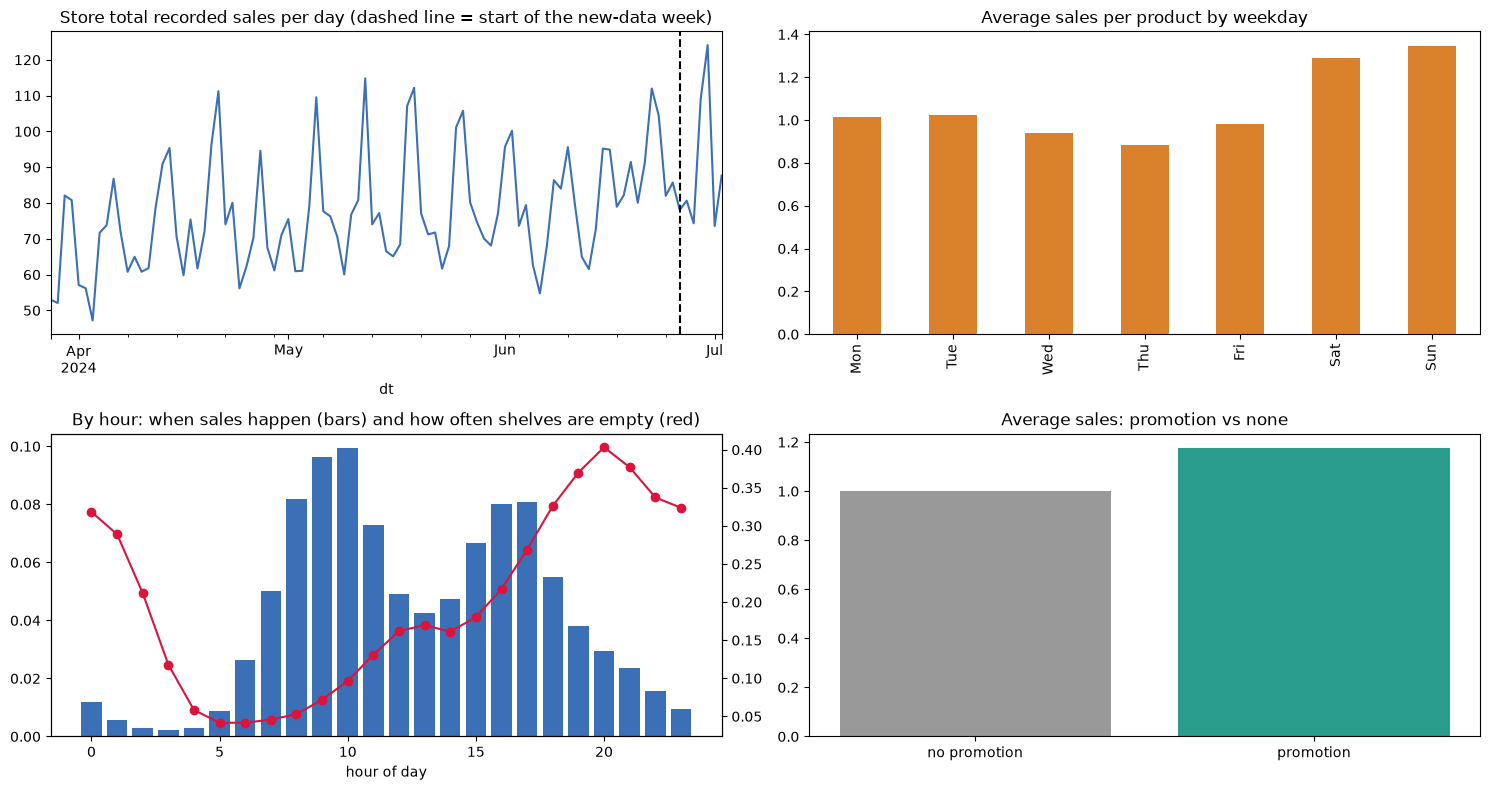

Days with at least one stock-out hour (6:00-22:00): 47% of product-days
Promotion lift in recorded sales: +17%
Correlation of daily sales with temperature / rain: 0.077 / 0.045


In [4]:
st = df[df.store_id == STORE]
H = np.stack(st.hours_stock_status.values).astype(bool); S = np.stack(st.hours_sale.values)
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
st.groupby("dt").sale_amount.sum().plot(ax=ax[0, 0], color="#3b6fb6"); ax[0, 0].axvline(df[df.split == "eval"].dt.min(), color="k", ls="--")
ax[0, 0].set_title("Store total recorded sales per day (dashed line = start of the new-data week)")
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
st.groupby(st.dt.dt.day_of_week).sale_amount.mean().set_axis(dow_names).plot.bar(ax=ax[0, 1], color="#d9822b")
ax[0, 1].set_title("Average sales per product by weekday")
ax[1, 0].bar(range(24), S.sum(axis=0) / S.sum(), color="#3b6fb6", label="share of daily sales")
ax2 = ax[1, 0].twinx(); ax2.plot(range(24), H.mean(axis=0), color="crimson", marker="o", label="share of products out of stock")
ax[1, 0].set_title("By hour: when sales happen (bars) and how often shelves are empty (red)"); ax[1, 0].set_xlabel("hour of day")
promo = st.groupby("activity_flag").sale_amount.mean()
ax[1, 1].bar(["no promotion", "promotion"], promo.values, color=["#999", "#2a9d8f"]); ax[1, 1].set_title("Average sales: promotion vs none")
plt.tight_layout(); plt.show()
print(f"Days with at least one stock-out hour (6:00-22:00): {(st.stock_hour6_22_cnt > 0).mean():.0%} of product-days")
print(f"Promotion lift in recorded sales: {promo[1] / promo[0] - 1:+.0%}")
print("Correlation of daily sales with temperature / rain:",
      round(st.sale_amount.corr(st.avg_temperature), 3), "/", round(st.sale_amount.corr(st.precpt), 3))

### 3.1 Data cleaning
An audit of the raw data found two issues:
- **Impossible discounts.** A discount of `0.0` would mean the item was free, and values above `1.0` would mean it was priced above normal. These are treated as recording errors and set to "no discount" (1.0).
- **`holiday_flag` is really a "non-working day" flag.** It covers weekends *and* Chinese public holidays. It is split into `is_weekend` and `public_holiday` so the models can tell them apart.

In [5]:
def clean(frame):
    # Fix impossible discounts and split the holiday flag. Used for history AND for new data as it arrives.
    frame = frame.copy()
    bad = (frame.discount <= 0) | (frame.discount > 1)
    frame.loc[bad, "discount"] = 1.0
    frame["dow"] = frame.dt.dt.day_of_week
    frame["is_weekend"] = (frame.dow >= 5).astype(int)
    frame["public_holiday"] = ((frame.holiday_flag == 1) & (frame.dow < 5)).astype(int)
    return frame, int(bad.sum())

df, n_bad = clean(df)
print(f"Invalid discount values fixed: {n_bad} rows ({n_bad / len(df):.2%})")
print("Public holidays found:", sorted(df.loc[df.public_holiday == 1, "dt"].dt.date.unique()))

Invalid discount values fixed: 0 rows (0.00%)
Public holidays found: [datetime.date(2024, 4, 4), datetime.date(2024, 4, 5), datetime.date(2024, 5, 1), datetime.date(2024, 5, 2), datetime.date(2024, 5, 3), datetime.date(2024, 6, 10)]


## 4. Recover the true demand hidden by stock-outs
When a shelf is empty, **recorded sales are lower than what customers wanted**. Treating sales as demand would make every later number (forecast, safety stock, reorder point) too low.

**Method.** On days when a product never ran out, we learn what share of its daily sales normally happens in each hour (its *hourly profile*). On a stock-out day, we take the sales from the hours when it *was* in stock and scale them up by the share of the day those hours normally cover:

`true demand ≈ sales in in-stock hours ÷ normal share of sales in those hours`

If the shelf was empty for almost the whole selling day (the in-stock hours normally carry under 25% of sales), the day tells us too little. Its demand is then filled with the product's typical demand over the previous two weeks.

**Test before trusting it.** We take fully stocked days where the true total is known, pretend the shelf emptied in the afternoon or evening, and check whether the method recovers the real total. The profiles are learned from the first 60 days and tested on later days, so the test is honest.

For the rest of the notebook, the profiles are learned only from days before the first forecasting test week (day 69). That way no later test sees information from its own week.

In [6]:
Hh = np.stack(df.hours_stock_status.values).astype(bool)     # True = out of stock in that hour
Sh = np.stack(df.hours_sale.values)
full_day = ~Hh.any(axis=1)

def hourly_profiles(mask):
    # Per-product hourly sales share, from fully stocked days in `mask`. Products with <5 such days use the overall profile.
    prof = pd.DataFrame(Sh[mask]); prof["p"] = df.product_id.values[mask]
    n_days = prof.groupby("p").size(); prof = prof.groupby("p").sum()
    prof = prof[(prof.sum(axis=1) > 0) & (n_days.reindex(prof.index) >= 5)]
    overall = Sh[mask].sum(axis=0) / Sh[mask].sum()
    return prof.div(prof.sum(axis=1), axis=0), overall

def profile_matrix(prof, overall, products):
    lookup = {p: v for p, v in zip(prof.index, prof.values)}
    return np.vstack([lookup.get(p, overall) for p in products])

# --- honest validation: profiles from days 0-59, tested on fully stocked days 60-89 ---
prof_v, overall_v = hourly_profiles(full_day & (df.t.values < 60))
test_rows = np.where(full_day & (df.t.values >= 60) & (df.t.values < T_TRAIN_END) & (Sh.sum(axis=1) > 0))[0]
vr = np.random.default_rng(SEED); test_rows = vr.choice(test_rows, min(15000, len(test_rows)), replace=False)
cut = vr.integers(10, 22, len(test_rows))                    # simulated stock-out starts between 10:00 and 21:00
Pv = profile_matrix(prof_v, overall_v, df.product_id.values[test_rows])
hours = np.arange(24)[None, :]; in_stock = hours < cut[:, None]
observed = (Sh[test_rows] * in_stock).sum(axis=1)
recovered = observed / np.maximum((Pv * in_stock).sum(axis=1), 0.2)
truth = Sh[test_rows].sum(axis=1)
val = pd.DataFrame({
    "error (WAPE)": [np.abs(observed - truth).sum() / truth.sum(), np.abs(recovered - truth).sum() / truth.sum()],
    "bias": [(observed - truth).sum() / truth.sum(), (recovered - truth).sum() / truth.sum()]},
    index=["Treat sales as demand", "Hourly-profile recovery"]).round(3)
display(val)

# --- apply to all days; profiles learned only from days before the first forecasting test (day 69) ---
PROFILE_END = 69
prof, overall = hourly_profiles(full_day & (df.t.values < PROFILE_END))

MIN_SHARE = 0.25   # if the in-stock hours normally cover less than 25% of a day's sales, the day tells us too little

def recover_demand(frame):
    # True-demand estimate for each row (needs hours_sale and hours_stock_status). Reused for new data.
    # Returns NaN where the shelf was empty for almost the whole selling day: those days are filled from history below.
    h = np.stack(frame.hours_stock_status.values).astype(bool); sh = np.stack(frame.hours_sale.values)
    pm = profile_matrix(prof, overall, frame.product_id.values)
    obs = (sh * ~h).sum(axis=1); share = (pm * ~h).sum(axis=1)
    est = np.maximum(obs / np.maximum(share, MIN_SHARE), sh.sum(axis=1))
    dem = np.where(~h.any(axis=1), sh.sum(axis=1), np.where(share >= MIN_SHARE, est, np.nan))
    return dem, h.any(axis=1)

def fill_unknown_days(frame):
    # Days with unknown demand get the median of the same product's previous 14 known days (past data only)
    frame = frame.sort_values(["sid", "t"]).copy()
    past = frame.groupby("sid").demand.transform(lambda x: x.shift(1).rolling(14, min_periods=3).median())
    first = frame.groupby("sid").demand.transform("median")                 # only used if a series starts with unknown days
    frame["demand_imputed"] = frame.demand.isna()
    frame["demand"] = frame.demand.fillna(past).fillna(first).fillna(0.0)
    return frame

df["demand"], df["censored"] = recover_demand(df)       # censored = shelf was empty for at least one hour that day
df = fill_unknown_days(df)
print(f"Days with too little in-stock time to estimate demand (filled from the product's recent history): {df.demand_imputed.mean():.1%}")
s_ = df[df.store_id == STORE]
print(f"Store {STORE}: recorded sales understate true demand by {1 - s_.sale_amount.sum() / s_.demand.sum():.1%} overall")

,error (WAPE),bias
Treat sales as demand,0.339,-0.339
Hourly-profile recovery,0.204,-0.010


Days with too little in-stock time to estimate demand (filled from the product's recent history): 4.8%
Store 308: recorded sales understate true demand by 18.8% overall


## 5. Step 1: Demand forecasting
**Features**, covering everything the slide lists:
- **History:** demand 7, 14, 21 and 28 days ago, plus 7-day and 28-day averages.
- **Seasonality:** weekday, weekend.
- **Promotions:** discount rate, promotion flag.
- **External factors:** public holidays, rain, temperature, humidity, wind.
- **Product category.**

All history features are at least 7 days old, so one model can forecast a full week ahead from a single day. This matters because the reorder point needs demand over the coming lead time.

**Six models are compared:**

| Type | Model |
|---|---|
| Simple baselines | Same weekday last week; 7-day moving average |
| Time series | Holt-Winters (exponential smoothing with weekly seasonality), one per product |
| Regression | Ridge (linear) regression; **Gradient Boosting** (tree ensemble), one model learned across all products |
| Deep learning | **LSTM**: reads the last 28 days and predicts the next 7, also learned across all products |

**Fair testing (walk-forward).** Each model is trained only on data before a cut-off day, then forecasts the next 7 days. Cut-offs at days 69, 76 and 83 are used to **choose** the model. The provided final week (days 90–96) is the **untouched final test**. This avoids the classic mistake of measuring accuracy on the same data the model was trained on.

**Metric.** WAPE (weighted absolute percentage error) = total absolute forecast error ÷ total demand. Lower is better; 0.30 means forecasts are off by 30% of demand on average. It is measured on the personal store's products. "In-stock days" scores only days where the shelf never ran empty, so the true demand is certain. "Bias" shows whether a model forecasts too high (+) or too low (−) overall.

**What the models know about the forecast week.** This matches how the system is used later:
- **Promotions and discounts are known in advance:** retailers plan them.
- **Weather is not known:** every model uses the previous week's average weather as its "weather forecast".

The errors measured here are therefore the errors to expect in real use. They feed straight into the safety stock.

In [7]:
def add_features(frame):
    frame = frame.sort_values(["sid", "t"]).copy()
    g = frame.groupby("sid").demand
    for L in (7, 14, 21, 28):
        frame[f"lag{L}"] = g.shift(L)
    frame["rm7"] = g.transform(lambda x: x.shift(7).rolling(7).mean())
    frame["rm28"] = g.transform(lambda x: x.shift(7).rolling(28, min_periods=14).mean())
    frame["scale"] = g.transform(lambda x: x.shift(7).expanding().mean()).clip(lower=0.05)
    return frame

df = add_features(df)
FEATS = ["dow", "is_weekend", "public_holiday", "discount", "activity_flag", "precpt", "avg_temperature",
         "avg_humidity", "avg_wind_level", "lag7", "lag14", "lag21", "lag28", "rm7", "rm28", "first_category_id"]
CAT_FEATS = ["dow", "first_category_id"]
HORIZON = 7

def fit_gb(train):
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, loss="poisson", random_state=0,
                                      categorical_features=[FEATS.index(c) for c in CAT_FEATS])
    return m.fit(train[FEATS], train.demand)

def fit_ridge(train):
    X = pd.get_dummies(train[FEATS], columns=CAT_FEATS, dtype=float)
    lagc = [c for c in X.columns if c.startswith(("lag", "rm"))]
    X[lagc] = X[lagc].div(train.scale.values, axis=0)
    return Ridge(alpha=1.0).fit(X, train.demand / train.scale), list(X.columns), lagc

def predict_ridge(model, test):
    r, cols, lagc = model
    X = pd.get_dummies(test[FEATS], columns=CAT_FEATS, dtype=float).reindex(columns=cols, fill_value=0)
    X[lagc] = X[lagc].div(test.scale.values, axis=0)
    return r.predict(X) * test.scale.values

In [8]:
# ---------- LSTM: 28 days of history (+ calendar/promo/weather) -> next 7 days ----------
HIST = 28
LSTM_COV = ["is_weekend", "public_holiday", "discount", "activity_flag", "precpt", "avg_temperature"]

class LSTMForecaster(nn.Module):
    def __init__(self, n_hist, n_future):
        super().__init__()
        self.lstm = nn.LSTM(n_hist, 48, batch_first=True)
        self.head = nn.Sequential(nn.Linear(48 + n_future, 64), nn.ReLU(), nn.Linear(64, HORIZON))
    def forward(self, x_hist, x_future):
        _, (h, _) = self.lstm(x_hist)
        return self.head(torch.cat([h[-1], x_future], dim=1))

def lstm_windows(frame, covs, dow1h, starts_fn):
    xh, xf, y, meta = [], [], [], []
    for sid, idx in frame.groupby("sid").indices.items():
        d = frame.demand.values[idx].astype(np.float32)
        for s in starts_fn(sid, len(idx)):
            h, f = slice(s - HIST, s), slice(s, s + HORIZON)
            scale = max(float(d[h].mean()), 0.1)
            xh.append(np.column_stack([np.minimum(d[h] / scale, 8.0), covs[idx][h], dow1h[idx][h]]))
            xf.append(np.column_stack([covs[idx][f], dow1h[idx][f]]).ravel())
            y.append(np.minimum(d[f] / scale, 8.0)); meta.append((sid, idx[s], scale))
    return torch.tensor(np.array(xh)), torch.tensor(np.array(xf)), torch.tensor(np.array(y)), meta

def lstm_forecast(frame, origin, epochs=10):
    # frame must contain every series with consecutive days 0..max; train on windows ending before origin
    frame = frame.sort_values(["sid", "t"]).reset_index(drop=True)
    known = frame.t < origin
    mu, sd = frame.loc[known, LSTM_COV].mean(), frame.loc[known, LSTM_COV].std().replace(0, 1)
    covs = ((frame[LSTM_COV] - mu) / sd).values.astype(np.float32)
    dow1h = np.eye(7, dtype=np.float32)[frame.dow.values]
    torch.manual_seed(SEED % (2**31))
    xh, xf, y, _ = lstm_windows(frame, covs, dow1h, lambda sid, n: range(HIST, origin - HORIZON + 1))
    net = LSTMForecaster(xh.shape[2], xf.shape[1]); opt = torch.optim.Adam(net.parameters(), 1e-3, weight_decay=1e-5)
    for _ in range(epochs):
        perm = torch.randperm(len(y))
        for b in range(0, len(y), 512):
            i = perm[b:b + 512]; opt.zero_grad()
            nn.functional.l1_loss(net(xh[i], xf[i]), y[i]).backward(); opt.step()
    store_sids = set(frame.loc[frame.store_id == STORE, "sid"])
    th, tf, _, meta = lstm_windows(frame, covs, dow1h, lambda sid, n: [origin] if sid in store_sids else [])
    with torch.no_grad():
        pred = net(th, tf).numpy() * np.array([m[2] for m in meta])[:, None]
    out = {}
    for (sid, row0, _), p in zip(meta, pred):
        for k in range(HORIZON):
            out[(sid, origin + k)] = float(p[k])
    return out

In [9]:
WEATHER = ["precpt", "avg_temperature", "avg_humidity", "avg_wind_level"]

def weather_as_known_at(frame, origin):
    # Replace weather on days >= origin with each series' average of the 7 days before origin (a persistence forecast)
    frame = frame.copy()
    recent = frame[(frame.t >= origin - 7) & (frame.t < origin)].groupby("sid")[WEATHER].mean()
    fut = frame.t >= origin
    for c in WEATHER:
        frame.loc[fut, c] = frame.loc[fut, "sid"].map(recent[c]).values
    return frame

def forecast_all_models(origin):
    # Train every model on days < origin and forecast the store's products for days origin..origin+6
    data = weather_as_known_at(df[df.t < origin + HORIZON], origin)
    train = data[(data.t < origin) & data.lag28.notna()]
    test = data[(data.t >= origin) & (data.t < origin + HORIZON) & (data.store_id == STORE)].copy()
    preds = {}
    preds["Same weekday last week"] = test.lag7.values
    last7 = df[(df.t >= origin - 7) & (df.t < origin)].groupby("sid").demand.mean()
    preds["7-day moving average"] = test.sid.map(last7).values
    hw = {}
    for sid, grp in test.groupby("sid"):
        hist = df[(df.sid == sid) & (df.t < origin)].sort_values("t").demand.values
        try:
            fc_hw = ExponentialSmoothing(hist, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit().forecast(len(grp))
        except Exception:                                       # fall back to last week's pattern if the fit fails
            fc_hw = hist[-7:][: len(grp)]
        hw.update(dict(zip(grp.sort_values("t").index, np.maximum(np.nan_to_num(fc_hw), 0))))
    preds["Holt-Winters (time series)"] = test.index.map(hw).values
    preds["Ridge regression"] = np.maximum(predict_ridge(fit_ridge(train), test), 0)
    preds["Gradient Boosting (ML)"] = fit_gb(train).predict(test[FEATS])
    lstm = lstm_forecast(data, origin)
    preds["LSTM (deep learning)"] = np.array([lstm[(s, t)] for s, t in zip(test.sid, test.t)])
    return test, preds

def score(test, preds):
    y, clean = test.demand.values, ~test.censored.values
    return {m: {"WAPE": np.abs(y - p).sum() / y.sum(), "WAPE in-stock days": np.abs(y[clean] - p[clean]).sum() / y[clean].sum(),
                "bias": (p - y).sum() / y.sum()} for m, p in preds.items()}

VAL_ORIGINS, TEST_ORIGIN = [69, 76, 83], T_TRAIN_END
t0 = time.time(); results, fold_preds = {}, {}
for o in VAL_ORIGINS + [TEST_ORIGIN]:
    test, preds = forecast_all_models(o); fold_preds[o] = (test, preds); results[o] = score(test, preds)
    print(f"cut-off day {o} done ({time.time() - t0:.0f}s)")

val_tbl = pd.concat({o: pd.DataFrame(results[o]).T for o in VAL_ORIGINS}).groupby(level=1).mean()
test_tbl = pd.DataFrame(results[TEST_ORIGIN]).T
summary = pd.DataFrame({"Validation WAPE (days 69-89)": val_tbl.WAPE, "Validation bias": val_tbl.bias,
                        "FINAL TEST WAPE (new week)": test_tbl.WAPE, "Final test WAPE, in-stock days": test_tbl["WAPE in-stock days"],
                        "Final test bias": test_tbl.bias}).sort_values("Validation WAPE (days 69-89)").round(3)
display(summary)
print("Note: the LSTM is competitive on fully stocked days, but on the final week it forecasts about "
      f"{abs(summary.loc['LSTM (deep learning)', 'Final test bias']):.0%} too low overall; 90 days is short for a deep network.")
BEST_MODEL = summary.index[0]
print("Most accurate model on validation weeks:", BEST_MODEL)
# The deployed forecaster must be a model that can use promotions/weather for future days: gradient boosting or ridge
DEPLOY_MODEL = BEST_MODEL if BEST_MODEL in ("Gradient Boosting (ML)", "Ridge regression") else "Gradient Boosting (ML)"
if DEPLOY_MODEL != BEST_MODEL:
    print(f"Deployed model: {DEPLOY_MODEL} (best of the models that use promotions and weather)")
FIT = {"Gradient Boosting (ML)": (fit_gb, lambda m, X: m.predict(X[FEATS])),
       "Ridge regression": (fit_ridge, lambda m, X: np.maximum(predict_ridge(m, X), 0))}[DEPLOY_MODEL]

cut-off day 69 done (46s)


cut-off day 76 done (101s)


cut-off day 83 done (169s)


cut-off day 90 done (245s)


,Validation WAPE (days 69-89),Validation bias,FINAL TEST WAPE (new week),"Final test WAPE, in-stock days",Final test bias
Gradient Boosting (ML),0.342,-0.026,0.321,0.415,0.011
LSTM (deep learning),0.343,-0.065,0.390,0.358,-0.269
Holt-Winters (time series),0.363,-0.013,0.333,0.410,-0.043
7-day moving average,0.376,-0.038,0.363,0.444,-0.017
Ridge regression,0.378,-0.003,0.348,0.422,-0.064
Same weekday last week,0.437,-0.038,0.377,0.503,-0.017


Note: the LSTM is competitive on fully stocked days, but on the final week it forecasts about 27% too low overall; 90 days is short for a deep network.
Most accurate model on validation weeks: Gradient Boosting (ML)


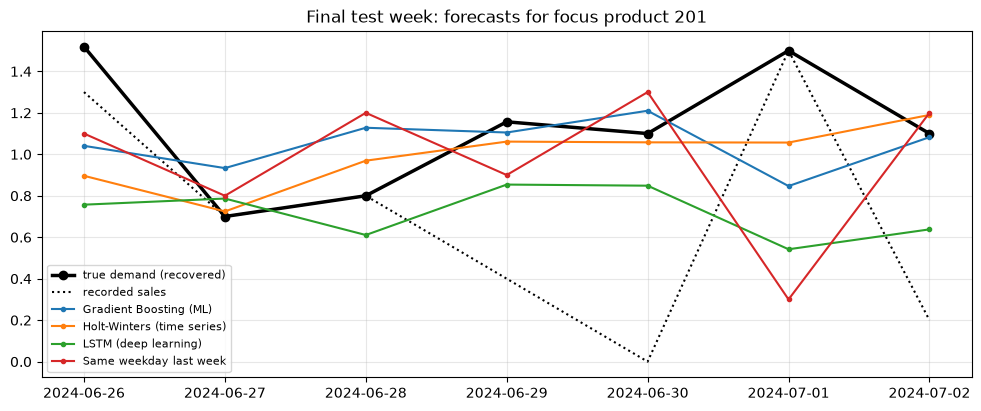

In [10]:
store_products = df.loc[df.store_id == STORE].groupby("product_id").demand.mean()
HERO = int(store_products[store_products >= store_products.median()].sample(1, random_state=SEED % 10_000).index[0])
test, preds = fold_preds[TEST_ORIGIN]
m = (test.product_id == HERO).values
plt.figure(figsize=(12, 4.5))
plt.plot(test.dt[m], test.demand[m], "ko-", lw=2.5, label="true demand (recovered)")
plt.plot(test.dt[m], test.sale_amount[m], "k:", label="recorded sales")
for name in ["Gradient Boosting (ML)", "Holt-Winters (time series)", "LSTM (deep learning)", "Same weekday last week"]:
    plt.plot(test.dt[m], preds[name][m], marker=".", label=name)
plt.title(f"Final test week: forecasts for focus product {HERO}"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

### 5.1 A forecaster that accepts new data
Slide 35 asks to *"keep the possibility of adding new data"* and to *"continuously update forecasts as new data arrives"*. `DemandForecaster` does both:
- `add_raw_data()` accepts new rows **in the original dataset format**. It cleans them, recovers true demand and stores them.
- `forecast()` re-trains on everything known so far and predicts the next 7 days.

For future days, promotions come from the planned promotion calendar where one exists (the dataset's own promotion flags). Otherwise no promotion is assumed. Weather is always last week's average.

In [11]:
PLANNED = df.set_index(["sid", "t"])[["discount", "activity_flag", "public_holiday"]]   # promotion calendar known in advance

def prepare_new_rows(raw):
    # Turn raw rows (original dataset format) into model-ready rows: clean, recover demand, attach ids
    new = raw.copy(); new["dt"] = pd.to_datetime(new["dt"])
    new, _ = clean(new)
    new["sid"] = [SID[(s, p)] for s, p in zip(new.store_id, new.product_id)]
    new["t"] = (new.dt - DAY0).dt.days
    new["demand"], new["censored"] = recover_demand(new)
    return new                                   # unknown days (NaN demand) are filled from history in add_raw_data

class DemandForecaster:
    def __init__(self, history):
        self.data = history.copy()
    def add_raw_data(self, raw_rows):
        new = prepare_new_rows(raw_rows)
        self.data = pd.concat([self.data, new], ignore_index=True).drop_duplicates(["sid", "t"], keep="last")
        self.data = fill_unknown_days(self.data)          # uses only days before each unknown day
        keys = set(zip(new.sid, new.t))
        return self.data[[k in keys for k in zip(self.data.sid, self.data.t)]]
    def _future_rows(self, start, days):
        # Rows for days not in the data yet (only the store's products are forecast)
        last = self.data[(self.data.t < start) & (self.data.store_id == STORE)]
        base = last.sort_values("t").groupby("sid").tail(7)
        have = set(zip(self.data.sid.values, self.data.t.values))
        rows = []
        for sid, g in base.groupby("sid"):
            ref = g.iloc[-1]
            for t in range(start, start + days):
                if (sid, t) in have:
                    continue
                d = ref["dt"] + pd.Timedelta(days=int(t - ref["t"])); dow = d.day_of_week
                plan_ = PLANNED.loc[(sid, t)] if (sid, t) in PLANNED.index else None   # planned promotions, if on the calendar
                rows.append({"sid": sid, "t": t, "dt": d, "store_id": ref["store_id"], "product_id": ref["product_id"],
                             "first_category_id": ref["first_category_id"], "dow": dow, "is_weekend": int(dow >= 5),
                             "public_holiday": int(plan_["public_holiday"]) if plan_ is not None else 0,
                             "activity_flag": int(plan_["activity_flag"]) if plan_ is not None else 0,
                             "discount": float(plan_["discount"]) if plan_ is not None else g.discount.median(),
                             **{c: g[c].mean() for c in WEATHER}, "demand": np.nan})
        return pd.DataFrame(rows)
    def forecast(self, origin, days=HORIZON, store_only=True):
        known = self.data[self.data.t < origin]
        future = self.data[(self.data.t >= origin) & (self.data.t < origin + days)].assign(demand=np.nan)
        frame = pd.concat([known, future, self._future_rows(origin, days)], ignore_index=True)
        frame = add_features(frame)
        fit_fn, predict_fn = FIT
        model = fit_fn(frame[(frame.t < origin) & frame.lag28.notna()])
        out = frame[(frame.t >= origin) & (frame.t < origin + days)]
        if store_only:
            out = out[out.store_id == STORE]
        return out.assign(forecast=predict_fn(model, out))[["sid", "product_id", "t", "dt", "forecast"]]

# Forecast errors of the chosen model on every walk-forward week: these feed the safety-stock calculations
errors = []
for o in VAL_ORIGINS + [TEST_ORIGIN]:
    tst, p = fold_preds[o]
    errors.append(pd.DataFrame({"product_id": tst.product_id.values, "t": tst.t.values,
                                "horizon": tst.t.values - o + 1, "error": tst.demand.values - p[DEPLOY_MODEL]}))
errors = pd.concat(errors)
print(f"Out-of-sample forecast errors collected: {len(errors)} ({errors.groupby('product_id').size().iloc[0]} per product)")

# Plan for the NEXT week (days 97-103) using all 97 known days
forecaster = DemandForecaster(df[df.t < 97])     # everything known after the final week
next_week = forecaster.forecast(97)
print("Next-week forecasts created for", next_week.product_id.nunique(), "products, days", next_week.t.min(), "-", next_week.t.max())

Out-of-sample forecast errors collected: 2044 (28 per product)


Next-week forecasts created for 73 products, days 97 - 103


## 6. The class calculator, as a baseline
This is the calculator from the class notebook, using its own logic on this store's data: average **recorded sales** as daily demand, a fixed lead time, and a fixed safety stock of 2 days of demand (the class example used 200 units on 100/day). Its weaknesses are what the next steps fix:
- demand is taken from censored sales
- uncertainty is ignored
- the safety stock is a guess
- the sensitivity analysis can only draw straight lines, because the formula is a simple sum

The class calculator gives no order quantity. Where one is needed later for simulation, it is **assumed** to be 2 days of demand.

Focus product 201: class calculator reorder point = 0.863 x 2 + 1.725 = 3.450


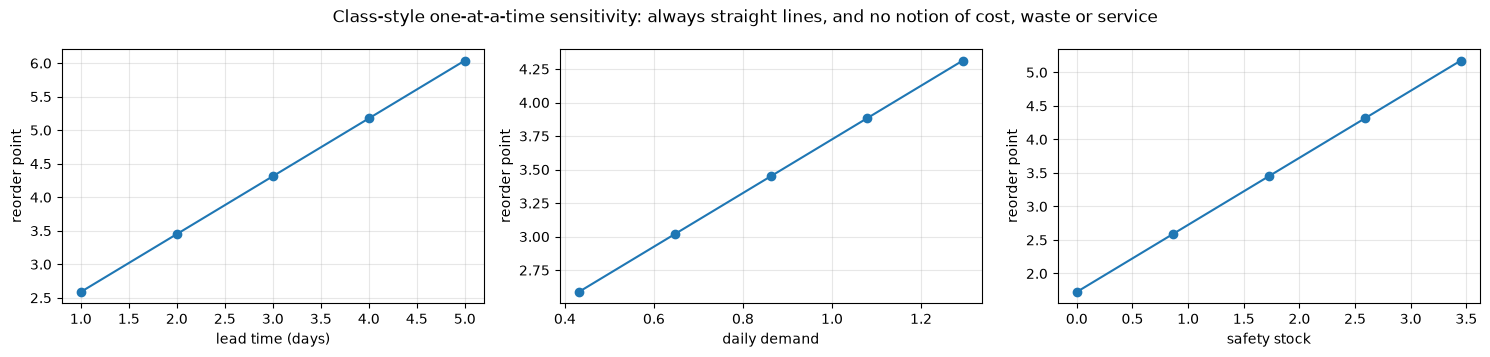

In [12]:
naive = df[(df.store_id == STORE) & (df.t < 97)].groupby("product_id").sale_amount.mean()
CLASS_LEAD, CLASS_SS_DAYS = 2, 2
class_rop = naive * CLASS_LEAD + CLASS_SS_DAYS * naive
print(f"Focus product {HERO}: class calculator reorder point = {naive[HERO]:.3f} x {CLASS_LEAD} + {CLASS_SS_DAYS * naive[HERO]:.3f} = {class_rop[HERO]:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, (lab, xs, f) in zip(ax, [("lead time (days)", np.arange(1, 6), lambda x: naive[HERO] * x + CLASS_SS_DAYS * naive[HERO]),
                                ("daily demand", np.linspace(.5, 1.5, 5) * naive[HERO], lambda x: x * CLASS_LEAD + CLASS_SS_DAYS * naive[HERO]),
                                ("safety stock", np.linspace(0, 4, 5) * naive[HERO], lambda x: naive[HERO] * CLASS_LEAD + x)]):
    a.plot(xs, f(xs), "o-"); a.set_xlabel(lab); a.set_ylabel("reorder point"); a.grid(alpha=.3)
fig.suptitle("Class-style one-at-a-time sensitivity: always straight lines, and no notion of cost, waste or service"); plt.tight_layout(); plt.show()

## 7. Step 2: Dynamic safety stock
### 7.1 The probabilistic formula (slide 35)
$$\text{Safety Stock} = Z\cdot\sqrt{\sigma_D^2\cdot \bar L + \bar D^2\cdot\sigma_L^2}\qquad\text{Reorder point} = \bar D\cdot\bar L + \text{Safety Stock}$$

- $\bar D$ = average daily demand from the **forecast**, bias-corrected (if the model tends to forecast 5% too low, $\bar D$ is raised by that amount).
- $\sigma_D$ = spread of the **forecast errors**. The slide calls this "demand standard deviation". Once we forecast, the uncertainty that matters is what the forecast cannot predict, not the raw ups and downs of sales. Both versions are shown in the table for comparison.
- $\bar L,\ \sigma_L$ = mean and spread of the supplier lead time.
- $Z$ = the service-level factor (95% → 1.645).

The first term inside the root is uncertainty from **demand**; the second is uncertainty from **delivery time**.

### 7.2 Monte Carlo simulation
The formula assumes demand follows a symmetric bell curve. Monte Carlo makes no such assumption. It simulates 20,000 possible futures, each with a random lead time and random forecast errors drawn from the model's real past errors, and reads off the level that covers 95% of them. Section 7.3 then runs it under named **risk scenarios** to show the buffer each one requires.

,avg demand/day,forecast error sd,raw demand sd,SS formula (raw demand sd),SS formula,ROP formula,SS Monte Carlo,ROP Monte Carlo,class ROP,MC vs formula
product,,,,,,,,,,
4,0.723,1.189,3.078,7.483,3.018,4.572,4.326,6.111,8.491,0.337
6,1.424,0.561,0.700,2.508,2.296,5.359,2.602,5.658,3.986,0.056
11,0.681,0.254,0.391,1.296,1.078,2.542,1.258,2.723,2.359,0.071
18,1.725,0.638,0.569,2.633,2.724,6.433,3.140,6.844,2.216,0.064
19,2.032,0.646,0.772,3.237,3.072,7.440,3.475,7.842,4.796,0.054
21,1.625,0.398,0.521,2.462,2.325,5.820,2.641,6.133,3.311,0.054
23,1.016,0.632,0.486,1.768,2.019,4.203,2.284,4.466,2.525,0.062
26,0.831,0.388,0.434,1.507,1.432,3.220,1.635,3.419,2.799,0.062
41,2.145,0.614,0.800,3.396,3.163,7.773,3.629,8.234,4.770,0.059


Across 73 products: Monte Carlo reorder point differs from the formula by 7.5% on average (range +4% to +34%).
The class calculator's reorder points are on average 26% lower than Monte Carlo's.
Products with a few extreme days (very uneven demand) show the biggest gap between formula and Monte Carlo: exactly the case where the bell-curve assumption of the formula is weakest.


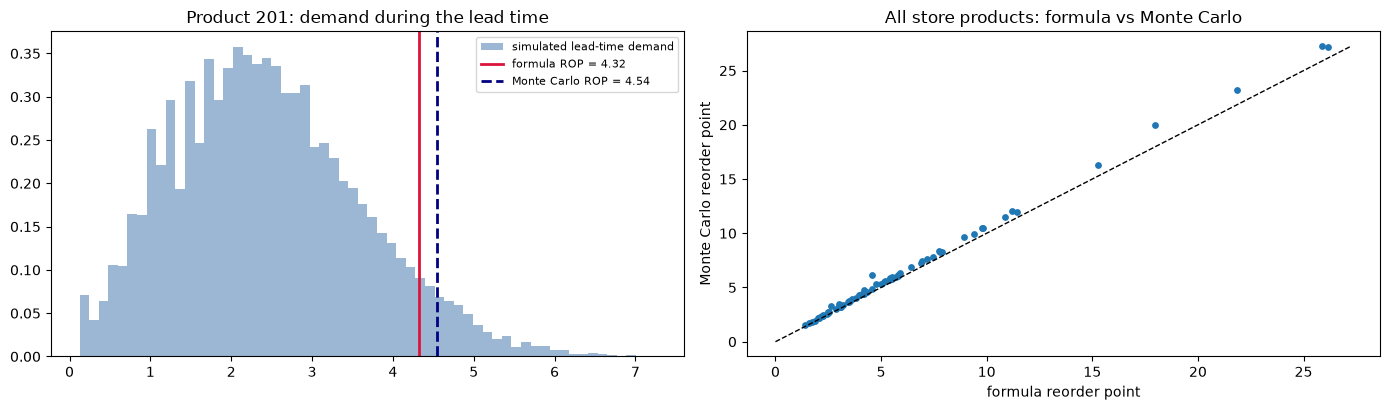

Using raw demand sd instead of forecast-error sd would change the store's total safety stock by +7%


In [13]:
MC_N = 20_000

def plan_inputs(product, fc_table=next_week, err_table=errors):
    fc = fc_table[fc_table.product_id == product].sort_values("t").forecast.values
    e = err_table[err_table.product_id == product].error.values
    return fc, e

def safety_stock_formula(fc, e, lt_mean=LT_MEAN, lt_sd=LT_SD, z=Z):
    d_bar = max(fc.mean() + e.mean(), 1e-6); s_d = e.std(ddof=1)
    ss = z * math.sqrt(s_d**2 * lt_mean + d_bar**2 * lt_sd**2)
    return dict(D_bar=d_bar, sigma_D=s_d, SS=ss, ROP=d_bar * lt_mean + ss)

def lead_time_demand_mc(fc, e, n=MC_N, lt_values=LT_VALUES, lt_probs=LT_PROBS, seed=SEED):
    g = np.random.default_rng(seed % (2**32))
    L = g.choice(lt_values, n, p=lt_probs); start = g.integers(0, len(fc), n)
    k = np.arange(lt_values.max())
    daily = np.maximum(fc[(start[:, None] + k[None, :]) % len(fc)] + g.choice(e, (n, len(k))), 0)
    return (daily * (k[None, :] < L[:, None])).sum(axis=1)

def safety_stock_mc(fc, e, service=SERVICE_LEVEL, **kw):
    ltd = lead_time_demand_mc(fc, e, **kw)
    rop = np.quantile(ltd, service)
    return dict(SS=rop - ltd.mean(), ROP=rop, ltd=ltd)

rows = []
for p in sorted(next_week.product_id.unique()):
    fc, e = plan_inputs(p); f = safety_stock_formula(fc, e); mc = safety_stock_mc(fc, e)
    raw_sd = df[(df.store_id == STORE) & (df.product_id == p) & (df.t < 97)].demand.std()
    rows.append({"product": p, "avg demand/day": f["D_bar"], "forecast error sd": f["sigma_D"], "raw demand sd": raw_sd,
                 "SS formula (raw demand sd)": Z * math.sqrt(raw_sd**2 * LT_MEAN + f["D_bar"]**2 * LT_SD**2), "SS formula": f["SS"],
                 "ROP formula": f["ROP"], "SS Monte Carlo": mc["SS"], "ROP Monte Carlo": mc["ROP"],
                 "class ROP": class_rop[p]})
plan = pd.DataFrame(rows).set_index("product")
plan["MC vs formula"] = plan["ROP Monte Carlo"] / plan["ROP formula"] - 1
display(plan.round(3).head(10))
print(f"Across {len(plan)} products: Monte Carlo reorder point differs from the formula by {plan['MC vs formula'].abs().mean():.1%} on average "
      f"(range {plan['MC vs formula'].min():+.0%} to {plan['MC vs formula'].max():+.0%}).")
d_ = (plan['class ROP'] / plan['ROP Monte Carlo'] - 1).mean()
print(f"The class calculator's reorder points are on average {abs(d_):.0%} {'lower' if d_ < 0 else 'higher'} than Monte Carlo's.")
print("Products with a few extreme days (very uneven demand) show the biggest gap between formula and Monte Carlo: "
      "exactly the case where the bell-curve assumption of the formula is weakest.")

fc_h, e_h = plan_inputs(HERO); f_h = safety_stock_formula(fc_h, e_h); mc_h = safety_stock_mc(fc_h, e_h)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(mc_h["ltd"], bins=60, color="#9bb7d4", density=True, label="simulated lead-time demand")
ax[0].axvline(f_h["ROP"], color="crimson", lw=2, label=f"formula ROP = {f_h['ROP']:.2f}")
ax[0].axvline(mc_h["ROP"], color="navy", lw=2, ls="--", label=f"Monte Carlo ROP = {mc_h['ROP']:.2f}")
ax[0].set_title(f"Product {HERO}: demand during the lead time"); ax[0].legend(fontsize=8)
ax[1].scatter(plan["ROP formula"], plan["ROP Monte Carlo"], s=15); lim = plan[["ROP formula", "ROP Monte Carlo"]].max().max()
ax[1].plot([0, lim], [0, lim], "k--", lw=1); ax[1].set_xlabel("formula reorder point"); ax[1].set_ylabel("Monte Carlo reorder point")
ax[1].set_title("All store products: formula vs Monte Carlo"); plt.tight_layout(); plt.show()
print(f"Using raw demand sd instead of forecast-error sd would change the store's total safety stock by "
      f"{plan['SS formula (raw demand sd)'].sum() / plan['SS formula'].sum() - 1:+.0%}")

### 7.3 Monte Carlo risk scenarios: how much buffer each risk needs
The same Monte Carlo is re-run for the focus product under supplier-risk scenarios and service targets. Each cell is the **safety stock** needed, with the formula's answer next to it. The last column is the full **reorder point** at 95%. A longer average lead time raises the reorder point even when the extra safety stock is small.

In [14]:
risk = {"Reliable supplier (always 2 days)": np.array([0, 1.0, 0, 0]), "Normal (base case)": LT_PROBS,
        "Unreliable supplier (often 3-4 days)": np.array([0.15, 0.30, 0.30, 0.25]),
        "Disruption (4 days half the time)": np.array([0.05, 0.20, 0.25, 0.50])}
rows = []
for name, probs in risk.items():
    lm = float((LT_VALUES * probs).sum()); ls = float(np.sqrt(((LT_VALUES - lm) ** 2 * probs).sum()))
    row = {"scenario": name, "mean lead time": lm}
    for sl in (0.90, 0.95, 0.99):
        row[f"MC safety stock @ {sl:.0%}"] = safety_stock_mc(fc_h, e_h, service=sl, lt_probs=probs)["SS"]
        row[f"formula SS @ {sl:.0%}"] = safety_stock_formula(fc_h, e_h, lm, ls, norm.ppf(sl))["SS"]
    row["MC reorder point @ 95%"] = safety_stock_mc(fc_h, e_h, service=0.95, lt_probs=probs)["ROP"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("scenario").round(3))
print("Note: 'Disruption' needs slightly LESS safety stock than 'Unreliable' because its lead time, though longer, is more predictable "
      "(usually 4 days). Its full reorder point is still the highest, because the average lead time is longest.")

,mean lead time,MC safety stock @ 90%,formula SS @ 90%,MC safety stock @ 95%,formula SS @ 95%,MC safety stock @ 99%,formula SS @ 99%,MC reorder point @ 95%
scenario,,,,,,,,
Reliable supplier (always 2 days),2.00,0.902,0.843,1.154,1.082,1.607,1.530,3.436
Normal (base case),2.15,1.573,1.452,2.087,1.863,3.044,2.635,4.540
Unreliable supplier (often 3-4 days),2.65,1.906,1.772,2.397,2.275,3.219,3.217,5.424
Disruption (4 days half the time),3.20,1.749,1.726,2.165,2.215,2.887,3.132,5.817


Note: 'Disruption' needs slightly LESS safety stock than 'Unreliable' because its lead time, though longer, is more predictable (usually 4 days). Its full reorder point is still the highest, because the average lead time is longest.


## 8. Step 3: Bayesian optimisation of the reorder point, under constraints
The formula answers *"what stock covers 95% of lead times?"*. It cannot answer *"what is the **best** reorder point?"*, because "best" depends on costs and limits the formula never sees. For fresh food the biggest blind spot is **spoilage**: extra safety stock that sits too long is thrown away.

**The inventory simulator** is a "digital twin" (a computer copy) of one product's shelf, run for 12 weeks × 300 random futures. It follows the standard **reorder-point rule**, written (s, Q): when stock drops to `s`, order `Q` units:
- Every evening, if stock on hand plus stock on order ≤ **reorder point `s`**, order **quantity `Q`**.
- The order arrives after a random lead time.
- Customers buy the oldest stock first. Unmet demand is lost (fresh-grocery customers buy elsewhere).
- Units older than the shelf life are thrown away.

**Objective:** minimise the average daily cost = holding + lost sales + waste + ordering.
**Constraints:**
- **Fill rate** (share of demand served) ≥ 95%
- Waste ≤ 5%
- Peak stock ≤ 6 days of demand in 95% of futures

Note that the fill rate is not the same as the formula's 95% service level. The formula's level means "the chance of not running out before a delivery arrives".

**Why Bayesian optimisation, instead of a manual parameter sweep.** Each evaluation is a full simulation, so trying every combination is wasteful.
- It fits a **Gaussian-process model**, a smooth statistical guess of how cost and the constraints change with `s` and `Q`.
- It picks the next point where an improvement is most likely, and avoids regions it predicts will break a constraint.
- Every candidate is tested on the same 300 random futures, so differences come from the policy, not luck.

Below we **check** it against random search and a brute-force grid. Then all policies are re-tested on 300 *new* futures. Where it can, the optimiser prefers policies a quarter of a percentage point inside the fill and waste limits, so that its answer still meets them on futures it has not seen. If no such policy exists, it takes the best one that meets the real limits.

The textbook comparison policy uses the **Economic Order Quantity (EOQ)**, the classic order size that balances ordering and holding cost. Plain EOQ ignores spoilage, so here it is already capped at the amount that can sell within the shelf life. Even so, the formula treats the reorder point and order size separately and never sees waste. The optimiser chooses both together with waste included.

In [15]:
def simulate(s, Q, fc, e, *, lt_values=LT_VALUES, lt_probs=LT_PROBS, shelf=SHELF_LIFE, p_cost=P_COST,
             h_cost=H_COST, w_cost=W_COST, k_cost=K_COST, n_paths=300, days=84, warm=14, seed=7):
    g = np.random.default_rng(seed)
    dem = np.maximum(fc[np.arange(days) % len(fc)][None, :] + g.choice(e, (n_paths, days)), 0.0)
    lead = g.choice(lt_values, (n_paths, days), p=lt_probs)
    stock = np.zeros((n_paths, shelf)); stock[:, 0] = s + Q            # stock by age (0 = fresh)
    pipe = np.zeros((n_paths, days + lt_values.max() + 1))             # units due to arrive on each day
    tot = dict(hold=0., lost=0., waste=0., orders=0., served=0., demand=0., received=0.)
    peak = np.zeros(n_paths)
    for d in range(days):
        arriving = pipe[:, d]; stock[:, 0] += arriving
        on_hand_morning = stock.sum(axis=1)
        need = dem[:, d].copy(); sold = np.zeros(n_paths)
        for a in range(shelf - 1, -1, -1):                              # sell oldest first (FIFO)
            take = np.minimum(stock[:, a], need); stock[:, a] -= take; need -= take; sold += take
        expired = stock[:, -1].copy(); stock[:, 1:] = stock[:, :-1].copy(); stock[:, 0] = 0
        on_hand = stock.sum(axis=1)
        position = on_hand + pipe[:, d + 1:].sum(axis=1)
        place = position <= s
        rows = np.where(place)[0]; pipe[rows, d + lead[rows, d]] += Q
        if d >= warm:
            tot["hold"] += on_hand.sum(); tot["lost"] += need.sum(); tot["waste"] += expired.sum()
            tot["orders"] += place.sum(); tot["served"] += sold.sum(); tot["demand"] += dem[:, d].sum()
            tot["received"] += arriving.sum(); peak = np.maximum(peak, on_hand_morning)
    n = n_paths * (days - warm)
    return dict(cost=(h_cost * tot["hold"] + p_cost * tot["lost"] + w_cost * tot["waste"] + k_cost * tot["orders"]) / n,
                fill_rate=tot["served"] / tot["demand"], waste_rate=tot["waste"] / max(tot["received"], 1e-9),
                peak_stock=float(np.percentile(peak, 95)), orders_per_week=7 * tot["orders"] / n)

def feasible(r, d_bar, min_fill=MIN_FILL_RATE, max_waste=MAX_WASTE, cap_days=CAPACITY_DAYS):
    return r["fill_rate"] >= min_fill and r["waste_rate"] <= max_waste and r["peak_stock"] <= cap_days * d_bar

def violation(r, d_bar, min_fill=MIN_FILL_RATE, max_waste=MAX_WASTE, cap_days=CAPACITY_DAYS):
    return max(min_fill - r["fill_rate"], 0) + max(r["waste_rate"] - max_waste, 0) + max(r["peak_stock"] / (cap_days * d_bar) - 1, 0)

def optimise(fc, e, d_bar, n_trials=40, sampler="gp", seed=SEED, warm_start=None, min_fill=MIN_FILL_RATE,
             max_waste=MAX_WASTE, cap_days=CAPACITY_DAYS, verbose=True, **sim_kw):
    nominal = (min_fill, max_waste, cap_days)                                     # the real business limits
    min_fill, max_waste = min_fill + OPT_MARGIN, max_waste - OPT_MARGIN           # the optimiser aims slightly inside them
    def objective(trial):
        s = trial.suggest_float("s", 0.0, 8 * d_bar); Q = trial.suggest_float("Q", 0.25 * d_bar, 6 * d_bar)
        r = simulate(s, Q, fc, e, **sim_kw); trial.set_user_attr("r", r); return r["cost"]
    def constraints(trial):
        r = trial.user_attrs["r"]
        return [min_fill - r["fill_rate"], r["waste_rate"] - max_waste, r["peak_stock"] - cap_days * d_bar]
    smp = (optuna.samplers.GPSampler(seed=seed % 10_000, constraints_func=constraints, deterministic_objective=True)
           if sampler == "gp" else optuna.samplers.RandomSampler(seed=seed % 10_000))
    study = optuna.create_study(direction="minimize", sampler=smp)
    if warm_start:                                              # start from yesterday's answer, kept inside today's search range
        study.enqueue_trial({"s": float(np.clip(warm_start["s"], 0.0, 8 * d_bar)),
                             "Q": float(np.clip(warm_start["Q"], 0.25 * d_bar, 6 * d_bar))})
    study.optimize(objective, n_trials=n_trials)
    ok_margin = [t for t in study.trials if feasible(t.user_attrs["r"], d_bar, min_fill, max_waste, cap_days)]
    ok_real = [t for t in study.trials if feasible(t.user_attrs["r"], d_bar, *nominal)]
    if ok_margin or ok_real:                # prefer policies with the safety margin, else any that meet the real limits
        best = min(ok_margin or ok_real, key=lambda t: t.value)
        best.set_user_attr("feasible", True); best.set_user_attr("with_margin", bool(ok_margin))
    else:                                   # nothing met every constraint: report the closest policy and say so
        best = min(study.trials, key=lambda t: (violation(t.user_attrs["r"], d_bar, *nominal), t.value))
        best.set_user_attr("feasible", False); best.set_user_attr("with_margin", False)
        if verbose:
            print(f"  note: no policy met every constraint in {n_trials} trials; showing the closest one")
    return study, best

def grid_check(fc, e, d_bar, n=30, min_fill=MIN_FILL_RATE, max_waste=MAX_WASTE, cap_days=CAPACITY_DAYS, **sim_kw):
    # Brute-force search used only to double-check the optimiser: best feasible cost, or None if nothing is feasible
    best = None
    for s in np.linspace(0, 8 * d_bar, n):
        for q in np.linspace(0.25 * d_bar, 6 * d_bar, n):
            r = simulate(s, q, fc, e, **sim_kw)
            if feasible(r, d_bar, min_fill, max_waste, cap_days) and (best is None or r["cost"] < best):
                best = r["cost"]
    return best

d_bar_h = f_h["D_bar"]
eoq = math.sqrt(2 * K_COST * d_bar_h / H_COST)
Q_textbook = min(eoq, d_bar_h * SHELF_LIFE)       # textbook EOQ, capped at what can sell within the shelf life
t0 = time.time(); study_gp, best_gp = optimise(fc_h, e_h, d_bar_h, n_trials=40, sampler="gp"); t_gp = time.time() - t0
study_rs, best_rs = optimise(fc_h, e_h, d_bar_h, n_trials=40, sampler="random", verbose=False)
print(f"Plain EOQ = {eoq:.2f}; capped at shelf-life demand → order quantity used for the textbook policy = {Q_textbook:.2f}")
print(f"Bayesian optimisation: 40 simulations in {t_gp:.1f}s → s = {best_gp.params['s']:.3f}, Q = {best_gp.params['Q']:.3f}, "
      f"cost = {best_gp.value:.4f}, meets all constraints: {best_gp.user_attrs['feasible']}, "
      f"with safety margin: {best_gp.user_attrs['with_margin']}")
print("Random search (same 40-simulation budget):", f"best cost = {best_rs.value:.4f} (s = {best_rs.params['s']:.3f}, "
      f"Q = {best_rs.params['Q']:.3f}), meets all constraints: {best_rs.user_attrs['feasible']}")

Plain EOQ = 6.17; capped at shelf-life demand → order quantity used for the textbook policy = 4.57
Bayesian optimisation: 40 simulations in 1.7s → s = 3.107, Q = 1.976, cost = 0.4599, meets all constraints: True, with safety margin: True
Random search (same 40-simulation budget): best cost = 0.6892 (s = 5.425, Q = 1.259), meets all constraints: False


Grid search: 1,600 simulations in 5.9s → best feasible cost 0.4620 at s = 3.279, Q = 1.969
Bayesian optimisation used 40 simulations instead of 1,600 and found a policy that is 0.5% cheaper than the grid's best (the grid only tests fixed steps, so it can miss the exact optimum)
Only 2.1% of the policies on the grid meet all three limits: the target is small, which is why a smart search helps


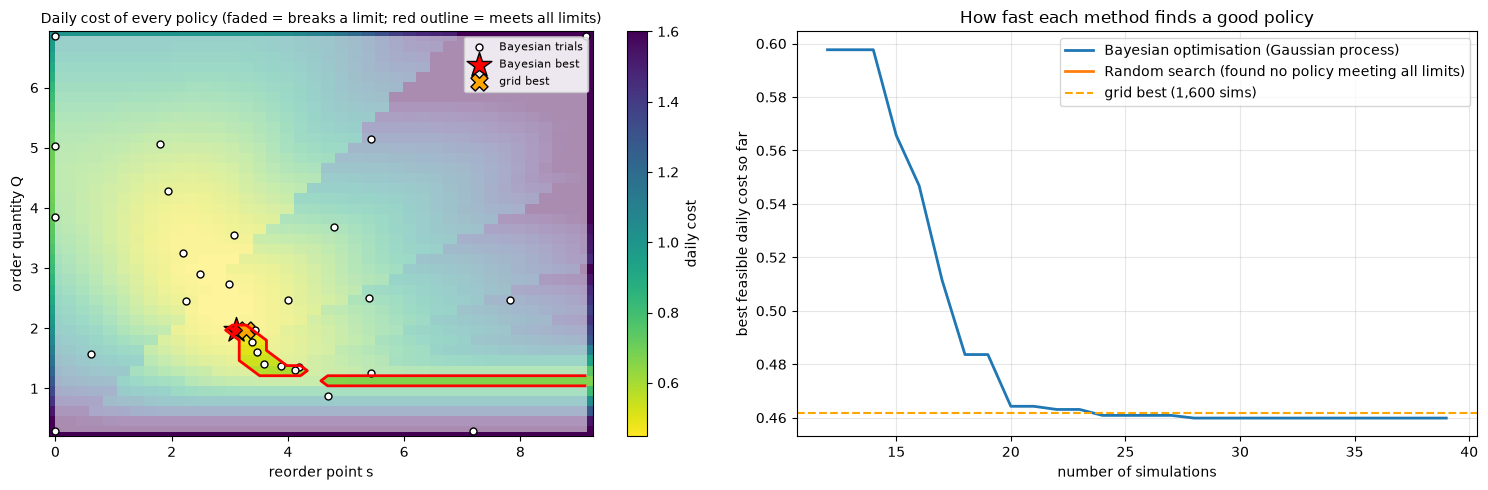

In [16]:
# ---- Check 1: brute-force grid of 1,600 simulations, using the same selection rule as the optimiser ----
TIGHT = dict(min_fill=MIN_FILL_RATE + OPT_MARGIN, max_waste=MAX_WASTE - OPT_MARGIN)
grid_tight = (np.inf, None, None)
s_grid = np.linspace(0, 8 * d_bar_h, 40); q_grid = np.linspace(0.25 * d_bar_h, 6 * d_bar_h, 40)
cost_map = np.full((40, 40), np.nan); ok_map = np.zeros((40, 40)); t0 = time.time(); grid_best = (np.inf, None, None)
for i, s in enumerate(s_grid):
    for j, q in enumerate(q_grid):
        r = simulate(s, q, fc_h, e_h)
        cost_map[j, i] = r["cost"]
        if feasible(r, d_bar_h):
            ok_map[j, i] = 1
            if r["cost"] < grid_best[0]: grid_best = (r["cost"], s, q)
            if feasible(r, d_bar_h, **TIGHT) and r["cost"] < grid_tight[0]: grid_tight = (r["cost"], s, q)
if grid_tight[1] is not None and best_gp.user_attrs["with_margin"]:
    grid_best = grid_tight                      # compare like with like: both chose a policy with the safety margin
print(f"Grid search: 1,600 simulations in {time.time() - t0:.1f}s → best feasible cost {grid_best[0]:.4f} at s = {grid_best[1]:.3f}, Q = {grid_best[2]:.3f}")
gap = best_gp.value / grid_best[0] - 1
print(f"Bayesian optimisation used 40 simulations instead of 1,600 and found a policy that is "
      f"{abs(gap):.1%} {'cheaper' if gap < 0 else 'more expensive'} than the grid's best "
      f"(the grid only tests fixed steps, so it can miss the exact optimum)")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
im = ax[0].pcolormesh(s_grid, q_grid, cost_map, shading="auto", cmap="viridis_r", vmax=np.nanpercentile(cost_map, 90))
plt.colorbar(im, ax=ax[0], label="daily cost")
ax[0].contourf(s_grid, q_grid, ok_map, levels=[-0.5, 0.5], colors="white", alpha=0.55)    # fade policies that break a limit
ax[0].contour(s_grid, q_grid, ok_map, levels=[0.5], colors="red", linewidths=2)
pts = np.array([[t.params["s"], t.params["Q"]] for t in study_gp.trials])
ax[0].scatter(pts[:, 0], pts[:, 1], c="white", edgecolor="k", s=25, label="Bayesian trials")
ax[0].scatter([best_gp.params["s"]], [best_gp.params["Q"]], marker="*", s=350, c="red", edgecolor="k", label="Bayesian best")
ax[0].scatter([grid_best[1]], [grid_best[2]], marker="X", s=150, c="orange", edgecolor="k", label="grid best")
ax[0].set_xlabel("reorder point s"); ax[0].set_ylabel("order quantity Q")
ax[0].set_title("Daily cost of every policy (faded = breaks a limit; red outline = meets all limits)", fontsize=10); ax[0].legend(fontsize=8)
print(f"Only {ok_map.mean():.1%} of the policies on the grid meet all three limits: the target is small, which is why a smart search helps")
def running_best(study):
    best, out = np.inf, []
    for t in study.trials:
        if feasible(t.user_attrs["r"], d_bar_h): best = min(best, t.value)
        out.append(best)
    return out
ax[1].plot(running_best(study_gp), label="Bayesian optimisation (Gaussian process)", lw=2)
rs_curve = running_best(study_rs)
ax[1].plot(rs_curve, lw=2, label="Random search" if np.isfinite(rs_curve[-1]) else "Random search (found no policy meeting all limits)")
ax[1].axhline(grid_best[0], color="orange", ls="--", label="grid best (1,600 sims)")
ax[1].set_xlabel("number of simulations"); ax[1].set_ylabel("best feasible daily cost so far"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title("How fast each method finds a good policy"); plt.tight_layout(); plt.show()

In [17]:
# ---- Check 2: compare all policies on 300 NEW random futures the optimiser never saw ----
policies = {
    "Class calculator (sales avg, fixed SS; Q assumed)": (class_rop[HERO], CLASS_LEAD * naive[HERO]),
    "Step 2 formula ROP + EOQ (capped)": (f_h["ROP"], Q_textbook),
    "Step 2 Monte Carlo ROP + EOQ (capped)": (mc_h["ROP"], Q_textbook),
    "Step 3 Bayesian-optimised (s, Q)": (best_gp.params["s"], best_gp.params["Q"]),
}
rows = []
for name, (s, q) in policies.items():
    r = simulate(s, q, fc_h, e_h, seed=2024)
    rows.append({"policy": name, "reorder point s": s, "order qty Q": q, **r, "meets all constraints": feasible(r, d_bar_h)})
compare = pd.DataFrame(rows).set_index("policy")
display(compare.round(3))
print("Note: a policy can look cheaper only by breaking a limit (e.g. allowing more waste). The comparison that matters "
      "is the cheapest policy that meets every limit.")

,reorder point s,order qty Q,cost,fill_rate,waste_rate,peak_stock,orders_per_week,meets all constraints
policy,,,,,,,,
"Class calculator (sales avg, fixed SS; Q assumed)",3.450,1.725,0.503,0.973,0.052,5.175,4.755,False
Step 2 formula ROP + EOQ (capped),4.318,4.567,0.757,0.944,0.274,8.878,2.266,False
Step 2 Monte Carlo ROP + EOQ (capped),4.540,4.567,0.769,0.949,0.281,9.071,2.301,False
"Step 3 Bayesian-optimised (s, Q)",3.107,1.976,0.459,0.955,0.039,5.071,4.019,True


Note: a policy can look cheaper only by breaking a limit (e.g. allowing more waste). The comparison that matters is the cheapest policy that meets every limit.


## 9. AI-driven sensitivity analysis
The class version changed one input and redrew a straight line. Here the **decision itself is optimised**: for each business condition below, Bayesian optimisation finds the best reorder point and order quantity again, so we see how the *optimal* decision moves.

For comparison, the last column shows the formula's reorder point. Notice what the formula **cannot** react to: shelf life and stock-out cost never appear in it. In the two service-target rows, the formula uses the target as its service level. The formula measures the chance of no stock-out per cycle and the optimiser measures the fill rate, so that comparison is approximate.

,optimal s,optimal Q,daily cost,fill rate,meets constraints,waste,formula ROP,note
scenario,,,,,,,,
Base case,3.107,1.976,0.460,0.954,True,0.038,4.318,
Reliable supplier (lead time always 2 days),2.541,2.977,0.321,0.979,True,0.034,3.365,
Unreliable supplier (often 3-4 days),3.963,1.639,0.532,0.954,True,0.046,5.301,
Shorter shelf life (3 days),9.135,1.170,0.738,0.940,False,0.082,4.318,no feasible policy exists (confirmed by grid s...
Longer shelf life (6 days),3.021,3.845,0.300,0.964,True,0.015,4.318,
Cheap stock-outs (cost 0.75),3.111,2.034,0.420,0.953,True,0.043,4.318,
Expensive stock-outs (cost 3.0),3.315,1.984,0.528,0.962,True,0.047,4.318,
Higher service target (fill ≥ 98%),4.013,1.451,0.559,0.981,False,0.050,4.781,no feasible policy exists (confirmed by grid s...
Lower service target (fill ≥ 90%),2.807,2.360,0.445,0.940,True,0.047,3.907,


Reading the table: the optimal reorder point barely moves with the stock-out cost, because the 95% fill-rate limit already decides how much protection is needed. Cost only matters once that limit is met. In impossible scenarios the row shows the closest policy found, not a true optimum. With a 3-day shelf life it orders about one day's demand every day (s is high and Q small).
Where no policy can meet every constraint, the business must relax one: accept more waste, a lower fill rate, or fix the root cause (e.g. a more reliable supplier). The optimiser shows the closest achievable policy.


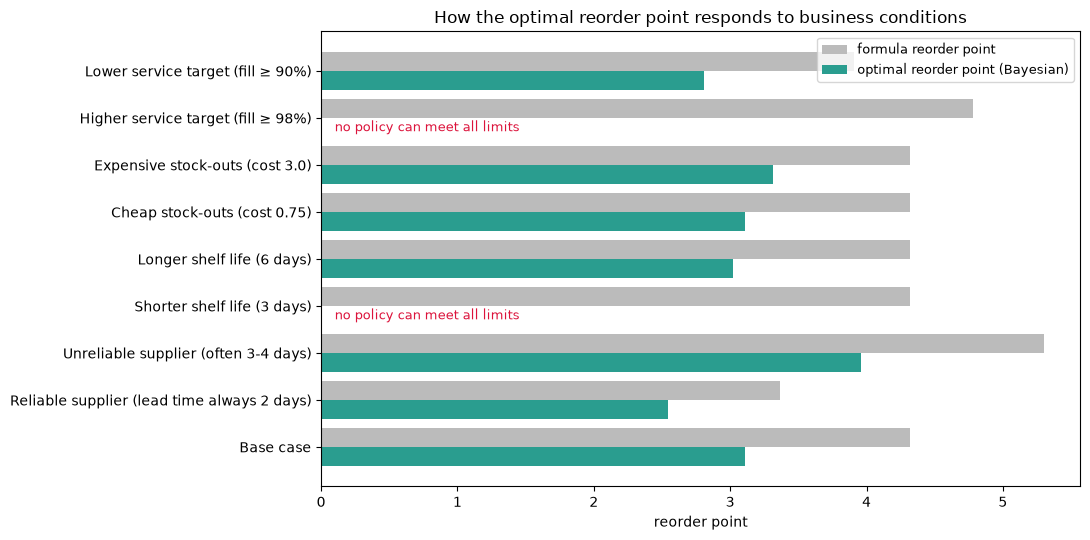

In [18]:
scenarios = [
    ("Base case", {}),
    ("Reliable supplier (lead time always 2 days)", dict(lt_probs=np.array([0, 1.0, 0, 0]))),
    ("Unreliable supplier (often 3-4 days)", dict(lt_probs=np.array([0.15, 0.30, 0.30, 0.25]))),
    ("Shorter shelf life (3 days)", dict(shelf=3)),
    ("Longer shelf life (6 days)", dict(shelf=6)),
    ("Cheap stock-outs (cost 0.75)", dict(p_cost=0.75)),
    ("Expensive stock-outs (cost 3.0)", dict(p_cost=3.0)),
    ("Higher service target (fill ≥ 98%)", dict(min_fill=0.98)),
    ("Lower service target (fill ≥ 90%)", dict(min_fill=0.90)),
]
rows = []
for name, kw in scenarios:
    sim_kw = {k: v for k, v in kw.items() if k in ("lt_probs", "shelf", "p_cost")}
    opt_kw = {k: v for k, v in kw.items() if k == "min_fill"}
    _, b = optimise(fc_h, e_h, d_bar_h, n_trials=50, verbose=False, **sim_kw, **opt_kw)
    check = "" if b.user_attrs["feasible"] else (
        "no feasible policy exists (confirmed by grid search)" if grid_check(fc_h, e_h, d_bar_h, **sim_kw, **opt_kw) is None
        else "grid search found a feasible policy the optimiser missed")
    lp = sim_kw.get("lt_probs", LT_PROBS); lm = float((LT_VALUES * lp).sum()); ls = float(np.sqrt(((LT_VALUES - lm) ** 2 * lp).sum()))
    z = norm.ppf(opt_kw.get("min_fill", SERVICE_LEVEL))
    rows.append({"scenario": name,
                 "optimal s": b.params["s"] if b else np.nan, "optimal Q": b.params["Q"] if b else np.nan,
                 "daily cost": b.value if b else np.nan,
                 "fill rate": b.user_attrs["r"]["fill_rate"] if b else np.nan, "meets constraints": b.user_attrs["feasible"],
                 "waste": b.user_attrs["r"]["waste_rate"] if b else np.nan,
                 "formula ROP": safety_stock_formula(fc_h, e_h, lm, ls, z)["ROP"], "note": check})
sens = pd.DataFrame(rows).set_index("scenario"); display(sens.round(3))
print("Reading the table: the optimal reorder point barely moves with the stock-out cost, because the 95% fill-rate limit already decides "
      "how much protection is needed. Cost only matters once that limit is met. In impossible scenarios the row shows the closest "
      "policy found, not a true optimum. With a 3-day shelf life it orders about one day's demand every day (s is high and Q small).")
if (~sens["meets constraints"]).any():
    print("Where no policy can meet every constraint, the business must relax one: accept more waste, a lower fill rate, "
          "or fix the root cause (e.g. a more reliable supplier). The optimiser shows the closest achievable policy.")
fig, ax = plt.subplots(figsize=(11, 5.5)); yy = np.arange(len(sens))
ax.barh(yy + 0.2, sens["formula ROP"], 0.4, color="#bbb", label="formula reorder point")
ok_s = sens["meets constraints"].values.astype(bool)
ax.barh(yy[ok_s] - 0.2, sens["optimal s"][ok_s], 0.4, color="#2a9d8f", label="optimal reorder point (Bayesian)")
for y_ in yy[~ok_s]:
    ax.text(0.1, y_ - 0.2, "no policy can meet all limits", va="center", fontsize=9, color="crimson")
ax.set_yticks(yy); ax.set_yticklabels(sens.index); ax.set_xlabel("reorder point"); ax.legend(fontsize=9)
ax.set_title("How the optimal reorder point responds to business conditions"); plt.tight_layout(); plt.show()

## 10. Real-time optimisation: the plan updates as each day of new data arrives
The final week (26 Jun – 2 Jul 2024) is now replayed day by day, as if it were live. Each morning the system:
1. receives yesterday's **raw** data (original format) and cleans it
2. re-trains the forecaster and forecasts the next 7 days
3. scores every earlier forecast that covered yesterday (1 to 7 days ahead) and adds those errors to the history
4. recalculates the formula and Monte Carlo reorder points
5. re-runs Bayesian optimisation, starting from yesterday's best answer

,forecast next 7d (avg),formula ROP,Monte Carlo ROP,Bayesian s,Bayesian Q,meets constraints,note,errors known,actual demand that day
date,,,,,,,,,
2024-06-26,1.050,4.230,4.406,3.218,1.731,True,,21,1.519
2024-06-27,1.021,4.195,4.365,2.953,1.919,True,,22,0.700
2024-06-28,1.087,4.302,4.484,3.071,2.063,True,,24,0.800
2024-06-29,1.049,4.032,4.213,2.984,1.806,True,,27,1.157
2024-06-30,1.050,4.006,4.180,2.902,1.904,True,,31,1.100
2024-07-01,1.084,4.011,4.188,2.868,1.939,True,,36,1.500
2024-07-02,1.121,4.477,4.691,3.185,2.371,True,,42,1.100


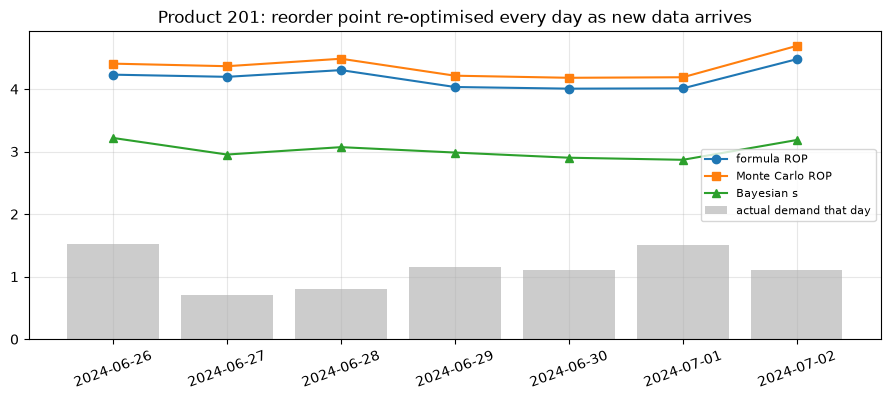

As the error history grows, the measured forecast uncertainty changes and the plan adapts. On days where the limits cannot all be met, the system flags it for a manager instead of silently ordering.


In [19]:
live = DemandForecaster(df[df.t < TEST_ORIGIN]); live_err = errors[errors.t < TEST_ORIGIN].copy()
log, prev_best, past_forecasts = [], None, []
raw_new_week["dt"] = pd.to_datetime(raw_new_week["dt"])
for day in range(TEST_ORIGIN, 97):
    if day > TEST_ORIGIN:
        raw_yesterday = raw_new_week[raw_new_week.dt == DAY0 + pd.Timedelta(days=day - 1)]
        new = live.add_raw_data(raw_yesterday)                                  # yesterday's RAW data arrives
        y = new[new.store_id == STORE].set_index("product_id").demand
        for origin_, fc_tab in past_forecasts:                                  # score every forecast that covered yesterday
            f_y = fc_tab[fc_tab.t == day - 1].set_index("product_id").forecast
            live_err = pd.concat([live_err, pd.DataFrame({"product_id": y.index, "t": day - 1, "horizon": day - origin_,
                                                          "error": (y - f_y.reindex(y.index)).values}).dropna()])
    last_fc = live.forecast(day); past_forecasts.append((day, last_fc))
    fc_d, e_d = plan_inputs(HERO, last_fc, live_err)
    f_d = safety_stock_formula(fc_d, e_d); mc_d = safety_stock_mc(fc_d, e_d)
    _, b = optimise(fc_d, e_d, f_d["D_bar"], n_trials=30, warm_start=prev_best, verbose=False)
    prev_best = dict(b.params)
    log.append({"date": df.loc[df.t == day, "dt"].iloc[0].date(), "forecast next 7d (avg)": fc_d.mean(),
                "formula ROP": f_d["ROP"], "Monte Carlo ROP": mc_d["ROP"],
                "Bayesian s": b.params["s"], "Bayesian Q": b.params["Q"], "meets constraints": b.user_attrs["feasible"],
                "note": "" if b.user_attrs["feasible"] else ("no policy can meet every limit today (confirmed by grid search)"
                         if grid_check(fc_d, e_d, f_d["D_bar"], n=25) is None else "grid search found a feasible policy"),
                "errors known": len(e_d),
                "actual demand that day": df[(df.t == day) & (df.product_id == HERO) & (df.store_id == STORE)].demand.iloc[0]})
live_log = pd.DataFrame(log).set_index("date"); display(live_log.round(3))
fig, ax = plt.subplots(figsize=(11, 4)); x = np.arange(len(live_log))
ax.bar(x, live_log["actual demand that day"], color="k", alpha=.2, label="actual demand that day")
for col, mk in [("formula ROP", "o"), ("Monte Carlo ROP", "s"), ("Bayesian s", "^")]:
    ax.plot(x, live_log[col], marker=mk, label=col)
ax.set_xticks(x); ax.set_xticklabels([str(d) for d in live_log.index], rotation=20)
ax.set_title(f"Product {HERO}: reorder point re-optimised every day as new data arrives"); ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()
print("As the error history grows, the measured forecast uncertainty changes and the plan adapts. On days where the limits "
      "cannot all be met, the system flags it for a manager instead of silently ordering.")

## 11. Store-wide replenishment plan for next week
The deliverable an operations team would use: for every product in the store, the forecast, safety stock and reorder point from both Step 2 methods, plus the Bayesian-optimised policy for the 10 highest-volume products. It is saved as a CSV.

In [20]:
top10 = plan["avg demand/day"].sort_values(ascending=False).head(10).index
for p in top10:
    fc, e = plan_inputs(p); d = plan.loc[p, "avg demand/day"]
    _, b = optimise(fc, e, d, n_trials=40, verbose=False)
    plan.loc[p, "Bayesian s"] = b.params["s"] if b else np.nan
    plan.loc[p, "Bayesian Q"] = b.params["Q"] if b else np.nan
    plan.loc[p, "Bayesian daily cost"] = b.value if b else np.nan
    plan.loc[p, "Bayesian meets constraints"] = b.user_attrs["feasible"]
out_csv = f"replenishment_plan_store{STORE}.csv"
plan.round(4).to_csv(out_csv)
display(plan.loc[top10].round(3))
print(f"Saved {out_csv} ({len(plan)} products)")

,avg demand/day,forecast error sd,raw demand sd,SS formula (raw demand sd),SS formula,ROP formula,SS Monte Carlo,ROP Monte Carlo,class ROP,MC vs formula,Bayesian s,Bayesian Q,Bayesian daily cost,Bayesian meets constraints
product,,,,,,,,,,,,,,
70,7.433,1.319,1.615,10.440,10.194,26.176,11.187,27.172,19.109,0.038,22.892,9.181,0.970,True
117,7.321,1.433,1.916,10.599,10.146,25.886,11.541,27.256,21.831,0.053,21.837,9.804,1.002,True
215,6.160,1.282,1.509,8.814,8.602,21.847,9.938,23.176,13.278,0.061,19.077,7.412,0.931,True
580,5.025,1.199,1.209,7.167,7.157,17.960,9.140,19.954,8.503,0.111,17.540,5.342,0.953,True
104,4.246,1.115,1.336,6.402,6.151,15.281,7.167,16.291,10.396,0.066,12.265,6.383,0.800,True
775,3.194,0.763,0.774,4.562,4.551,11.419,5.136,11.997,7.109,0.051,8.986,5.122,0.659,True
122,3.118,0.788,0.932,4.643,4.485,11.189,5.390,12.085,5.207,0.080,9.082,4.854,0.691,True
114,3.029,0.745,0.886,4.489,4.337,10.850,4.994,11.496,7.875,0.060,8.559,4.785,0.645,True
600,2.773,0.490,0.588,3.881,3.801,9.762,4.522,10.478,2.742,0.073,7.961,4.461,0.602,True


Saved replenishment_plan_store308.csv (73 products)


## 12. Results summary

In [21]:
base = compare.loc["Step 2 formula ROP + EOQ (capped)"]; opt = compare.loc["Step 3 Bayesian-optimised (s, Q)"]; cls = compare.loc["Class calculator (sales avg, fixed SS; Q assumed)"]
ok_ = lambda r: "meets all constraints" if r["meets all constraints"] else "BREAKS a constraint"
print(f"Personal slice: store {STORE}, {len(plan)} products; focus product {HERO}")
print(f"Stock-out correction: recorded sales understate true demand by {1 - s_.sale_amount.sum() / s_.demand.sum():.1%}")
print(f"Step 1  best forecaster: {BEST_MODEL}; final-test WAPE {summary.loc[BEST_MODEL, 'FINAL TEST WAPE (new week)']:.1%} "
      f"vs {summary.loc['Same weekday last week', 'FINAL TEST WAPE (new week)']:.1%} for the 'same weekday last week' baseline")
print(f"Step 2  focus product: formula ROP {f_h['ROP']:.2f}, Monte Carlo ROP {mc_h['ROP']:.2f}; class calculator {class_rop[HERO]:.2f}")
print("Step 3  tested on 300 new futures:")
for name, r in [("Bayesian-optimised", opt), ("Formula ROP + EOQ", base), ("Class calculator", cls)]:
    print(f"        {name:<20} cost {r.cost:.3f}/day, fill {r.fill_rate:.1%}, waste {r.waste_rate:.1%} → {ok_(r)}")
print(f"        Bayesian optimisation (40 runs) vs 1,600-run grid search: {best_gp.value / grid_best[0] - 1:+.1%} cost")

Personal slice: store 308, 73 products; focus product 201
Stock-out correction: recorded sales understate true demand by 18.8%
Step 1  best forecaster: Gradient Boosting (ML); final-test WAPE 32.1% vs 37.7% for the 'same weekday last week' baseline
Step 2  focus product: formula ROP 4.32, Monte Carlo ROP 4.54; class calculator 3.45
Step 3  tested on 300 new futures:
        Bayesian-optimised   cost 0.459/day, fill 95.5%, waste 3.9% → meets all constraints
        Formula ROP + EOQ    cost 0.757/day, fill 94.4%, waste 27.4% → BREAKS a constraint
        Class calculator     cost 0.503/day, fill 97.3%, waste 5.2% → BREAKS a constraint
        Bayesian optimisation (40 runs) vs 1,600-run grid search: -0.5% cost


## 13. Assumptions and limitations
- **Lead times, costs and constraints are assumptions.** The dataset has no supplier data, so they are set in Section 1 and can be changed. The method does not depend on the specific values.
- **Units are scaled.** Dingdong multiplied all sales by a hidden constant, so quantities are in "scaled units". Ratios and comparisons are unaffected.
- **Short history.** 90 days gives no yearly seasonality, and limits the LSTM, which is why one model is trained across many products.
- **Future promotions and weather.** All forecasts, including the tests, treat promotions as known in advance and use last week's average as the weather forecast. For the week after the data ends there is no promotion calendar, so no promotion is assumed. A real weather forecast would improve accuracy.
- **"Real time" is a replay.** The final week is replayed day by day to show the system updating; a live deployment would run the same loop on a schedule.
- **Simulation assumptions.** The simulator assumes lost sales (customers do not wait) and first-in-first-out selling, which suit fresh groceries.
- **Demand recovery** relies on each product's typical hourly pattern. It was validated against known days (Section 4), but it remains an estimate.

## 14. Data-integration checks
A final audit that the data flows through the code correctly. Each line below is a test, and the cell stops with an error if any test fails. The checks cover:
- **Loading:** every loaded row matches the raw files exactly.
- **Completeness:** each product has all 97 days, with no gaps or duplicates.
- **Field values:** hourly sales add up to daily sales, and discounts and holiday flags are valid.
- **Demand recovery:** never negative, never below recorded sales, and equal to sales on fully stocked days.
- **No look-ahead:** every model input uses data at least 7 days old, and forecasts use no future weather.
- **New data:** raw new data passes through exactly the same steps as the history.
- **Outputs:** the forecast and plan outputs are complete and consistent.
- **Simulator:** it behaves sensibly at the extremes.

In [22]:
results = []
def check(name, cond, detail=""):
    results.append((("PASS" if cond else "FAIL"), name, detail))

# 1. What was loaded matches the raw files exactly
raw_all = pd.concat([pd.read_parquet(DATA_DIR / f"{n}.parquet", filters=[("store_id", "in", POOL_STORES)]) for n in ("train", "eval")])
check("row count equals raw files", len(df) == len(raw_all), f"{len(df)} vs {len(raw_all)}")
m = df[["store_id", "product_id", "dt", "sale_amount"]].assign(dt=df.dt.dt.strftime("%Y-%m-%d")).merge(
    raw_all[["store_id", "product_id", "dt", "sale_amount"]], on=["store_id", "product_id", "dt"], suffixes=("", "_raw"))
check("every row matches a raw row", len(m) == len(df), f"{len(m)} matched")
check("sales values identical to raw", np.allclose(m.sale_amount, m.sale_amount_raw), f"max diff {np.abs(m.sale_amount - m.sale_amount_raw).max()}")
check("only the chosen stores were loaded", set(df.store_id) == set(POOL_STORES))

# 2. Time index and ids
per = df.groupby("sid").t.agg(["count", "min", "max", "nunique"])
check("every series has all 97 days", (per["count"] == 97).all() and (per["nunique"] == 97).all(), per["count"].describe().to_dict())
check("days run 0..96 with no gaps", (per["min"] == 0).all() and (per["max"] == 96).all())
check("no duplicate (series, day)", not df.duplicated(["sid", "t"]).any())
check("one sid per store-product", df.groupby("sid")[["store_id", "product_id"]].nunique().max().max() == 1 and len(SID) == df.sid.nunique())
check("t agrees with calendar date", ((df.dt - DAY0).dt.days == df.t).all())
check("split labels match dates", (df.loc[df.split == "eval", "t"].min() == 90) and (df.loc[df.split == "train", "t"].max() == 89))
check("store slice has 73 products x 97 days", (df.store_id == STORE).sum() == 73 * 97, int((df.store_id == STORE).sum()))

# 3. Field-level integrity
hs = np.stack(df.hours_sale.values); hst = np.stack(df.hours_stock_status.values)
check("24 hourly values per row", hs.shape[1] == 24 and hst.shape[1] == 24)
check("hourly sales sum to daily sales", np.allclose(hs.sum(axis=1), df.sale_amount), f"max diff {np.abs(hs.sum(axis=1) - df.sale_amount).max():.2e}")
check("stock status only 0/1", set(np.unique(hst)) <= {0, 1})
check("discounts all within (0, 1]", ((df.discount > 0) & (df.discount <= 1)).all())
check("is_weekend matches weekday", (df.is_weekend == (df.dt.dt.day_of_week >= 5)).all())
check("public holidays are weekdays flagged by the dataset", ((df.public_holiday == 1) <= ((df.holiday_flag == 1) & (df.dow < 5))).all())
check("no missing weather", df[WEATHER].notna().all().all())

# 4. Demand recovery
check("no missing demand", df.demand.notna().all())
check("demand never negative", (df.demand >= 0).all())
known = ~df.demand_imputed
check("recovered demand >= recorded sales (estimated days)", (df.demand[known] >= df.sale_amount[known] - 1e-9).all())
check("uncensored days: demand == sales", np.allclose(df.demand[~df.censored], df.sale_amount[~df.censored]))
check("imputed days are all censored", df.censored[df.demand_imputed].all())
check("imputed share is small", df.demand_imputed.mean() < 0.10, f"{df.demand_imputed.mean():.1%}")

# 5. Features: correct and no look-ahead
smp = df[df.lag28.notna()].sample(2000, random_state=1)
look = df.set_index(["sid", "t"]).demand
check("lag7 = demand 7 days earlier", np.allclose(smp.lag7, [look[(s, t - 7)] for s, t in zip(smp.sid, smp.t)]))
check("lag28 = demand 28 days earlier", np.allclose(smp.lag28, [look[(s, t - 28)] for s, t in zip(smp.sid, smp.t)]))
r7 = [np.mean([look[(s, t - k)] for k in range(7, 14)]) for s, t in zip(smp.sid, smp.t)]
check("rm7 = mean of days t-13..t-7 (no recent leak)", np.allclose(smp.rm7, r7))
check("no missing features in training rows", df.loc[df.lag28.notna(), FEATS].notna().all().all())

# 6. Forecast evaluation used weather NOT known in advance
d90 = weather_as_known_at(df[df.t < 97], 90)
fut = d90.t >= 90
check("test-week weather replaced by last-week average", not np.allclose(d90.loc[fut, "avg_temperature"].values, df.loc[df.t.between(90, 96), "avg_temperature"].values))
check("history weather untouched", np.allclose(d90.loc[~fut, "avg_temperature"].values, df.loc[df.t < 90, "avg_temperature"].values))

# 7. New-raw-data path reproduces the main pipeline
fresh = DemandForecaster(df[df.t < 96]); new = fresh.add_raw_data(raw_new_week[raw_new_week.dt == DAY0 + pd.Timedelta(days=96)])
ref = df[df.t == 96].set_index("sid").sort_index(); got = new.set_index("sid").sort_index()
check("raw path: same rows", set(ref.index) == set(got.index), f"{len(got)} rows")
ok_rows = ~ref.demand_imputed.reindex(got.index).values
check("raw path: same demand on estimated days", np.allclose(got.demand.values[ok_rows], ref.demand.reindex(got.index).values[ok_rows]))
check("raw path: same discount/holiday/weekend", all(np.allclose(got[c].values, ref[c].reindex(got.index).values) for c in ["discount", "public_holiday", "is_weekend", "activity_flag"]))

# 8. Outputs
check("next-week forecasts: 73 products x 7 days, no NaN, >= 0", len(next_week) == 73 * 7 and next_week.forecast.notna().all() and (next_week.forecast >= 0).all())
check("forecast errors: 28 per product, no NaN", (errors.groupby("product_id").size() == 28).all() and errors.error.notna().all())
plan_csv = pd.read_csv(out_csv)
check("plan CSV: 73 products", len(plan_csv) == 73)
check("plan CSV: no missing core numbers", plan_csv[["avg demand/day", "SS formula", "ROP formula", "SS Monte Carlo", "ROP Monte Carlo"]].notna().all().all())
check("plan CSV: reorder point >= safety stock >= 0", ((plan_csv["ROP formula"] >= plan_csv["SS formula"]) & (plan_csv["SS formula"] >= 0)).all())
check("plan CSV: Bayesian results for exactly 10 products, all within limits", plan_csv["Bayesian s"].notna().sum() == 10 and plan_csv["Bayesian meets constraints"].dropna().astype(bool).all())

# 9. Simulator sanity
big = simulate(20 * d_bar_h, 2 * d_bar_h, fc_h, e_h); none_ = simulate(0, 0.1 * d_bar_h, fc_h, e_h)
check("simulator: huge stock -> fill ~100%", big["fill_rate"] > 0.99, f"{big['fill_rate']:.3f}")
check("simulator: almost no stock -> low fill", none_["fill_rate"] < 0.3, f"{none_['fill_rate']:.3f}")
fills = [simulate(s, 1.5 * d_bar_h, fc_h, e_h)["fill_rate"] for s in np.linspace(0, 6 * d_bar_h, 8)]
check("simulator: fill rate rises with reorder point", all(b >= a - 1e-9 for a, b in zip(fills, fills[1:])))
check("simulator: same seed -> identical result", simulate(3, 1.5, fc_h, e_h) == simulate(3, 1.5, fc_h, e_h))
mc_vs_formula = abs(lead_time_demand_mc(fc_h, e_h).mean() - f_h["D_bar"] * LT_MEAN) / (f_h["D_bar"] * LT_MEAN)
check("Monte Carlo mean lead-time demand agrees with D_bar x L_mean (within 10%)", mc_vs_formula < 0.10, f"{mc_vs_formula:.1%}")

audit = pd.DataFrame(results, columns=["result", "check", "detail"])
counts = audit.result.value_counts().to_dict(); print(counts); display(audit)
assert "FAIL" not in counts, "a data-integration check failed: see the table above"
print(f"All {len(audit)} data-integration checks passed.")

{'PASS': 44}


,result,check,detail
0,PASS,row count equals raw files,242403 vs 242403
1,PASS,every row matches a raw row,242403 matched
2,PASS,sales values identical to raw,max diff 0.0
3,PASS,only the chosen stores were loaded,
4,PASS,every series has all 97 days,"{'count': 2499.0, 'mean': 97.0, 'std': 0.0, 'm..."
5,PASS,days run 0..96 with no gaps,
6,PASS,"no duplicate (series, day)",
7,PASS,one sid per store-product,
8,PASS,t agrees with calendar date,
9,PASS,split labels match dates,


All 44 data-integration checks passed.
